# 07 Seq2Seq完整训练、预测与Transformer概览

本篇对应网盘资料 `03-视频/day07`。已核对当天 **14 个视频文件名**：前 10 个围绕英译法 Seq2Seq 案例的注意力解码、Teacher Forcing、单批次/完整训练、预测和注意力图；后 4 个引入 Transformer 的由来、文字结构和架构图。在线阅读了 `07-案例Seq2Seq英译法案例.pdf` 第 41—63 页，以及 `08-Tranformer架构和实现.pdf` 第 1—20 页。视频未逐节转录。

课程原始英法语料与原始代码未读取，因此下面用 12 组独立编写的短句复现接口和训练流程。它们用于理解张量形状、梯度和推理循环；课程的 10,599 对语料、2803/4345 词表是课件报告值，本篇没有重新统计。图片均为自绘或实验结果，以 attachment 嵌入当前文件，无需配套图片目录。

沿用前篇格式：全部为 Markdown 单元；Python 代码块按顺序复制到同一 Python/Jupyter 会话执行即可，本篇自包含，无需先运行06。依赖：`numpy`、`torch`、`matplotlib`。本篇包含训练流程、shape 追踪、保存/重载、预测、热力图与 Transformer 架构预览。

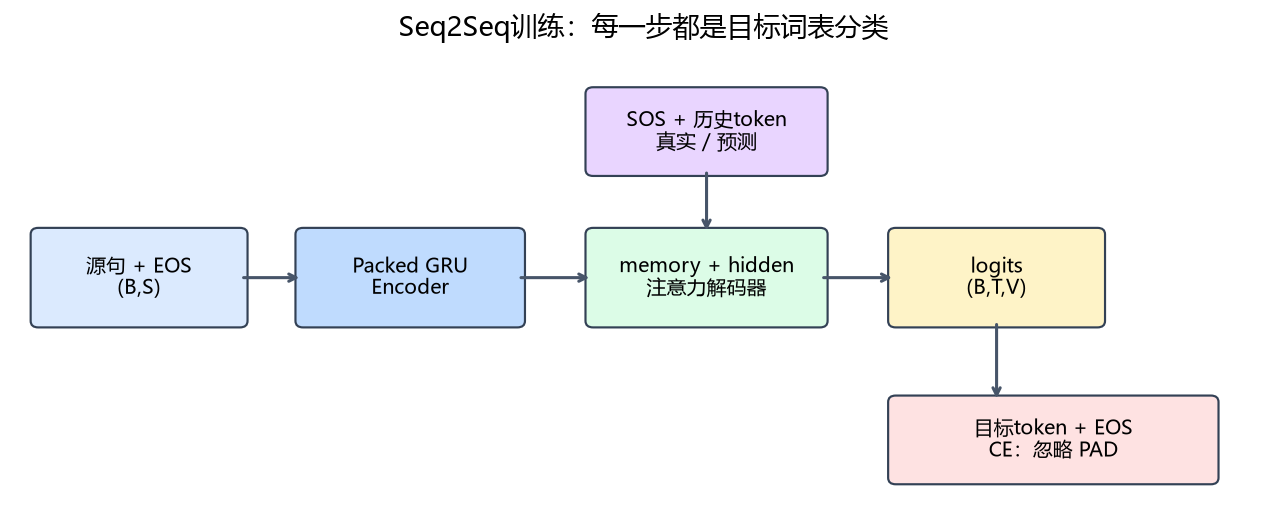


## 1. 运行环境与随机种子

Seq2Seq 训练至少涉及词表、编码器、解码器、损失函数和推理策略。先固定随机种子，再明确本篇使用 CPU，便于复现实验；如果改用 GPU，模型和 batch 必须一起移动到同一设备。

```python
import io, math, platform, random, re, unicodedata
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

SEED = 2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)
DEVICE = torch.device("cpu")
print("Python:", platform.python_version())
print("NumPy:", np.__version__, "PyTorch:", torch.__version__)
print("device:", DEVICE, "CUDA available:", torch.cuda.is_available())
```

```text
Python: 3.12.13
NumPy: 1.26.4 PyTorch: 2.14.1+cpu
device: cpu CUDA available: False
```


## 2. 语料、分词与词表

目标序列必须包含 `EOS`，否则解码器无法知道何时停止。`SOS` 只作为解码器第一步输入，`PAD` 只用于把不同长度的句子拼成 batch，并在损失函数中忽略。词表只从训练集建立，避免验证集或测试集的信息泄漏；未知词映射到 `UNK`。

课程代码中常见的 `split(' ')` 会把连续空格变成空 token，也无法稳妥处理法语重音和内部撇号。这里先做 Unicode NFC 规范化，再用正则保留 `j'ai` 这样的词。

```python
PAD, SOS, EOS, UNK = 0, 1, 2, 3
SPECIALS = ["<PAD>", "<SOS>", "<EOS>", "<UNK>"]
TOKEN_RE = re.compile(r"[^\W\d_]+(?:'[^\W\d_]+)*|[.!?]", re.UNICODE)

RAW_PAIRS = [
    ("Go!", "Va !"), ("I am cold.", "J'ai froid."),
    ("I am tired.", "Je suis fatigué."), ("He is calm.", "Il est calme."),
    ("She is ready.", "Elle est prête."), ("We are here.", "Nous sommes ici."),
    ("Thank you.", "Merci."), ("They are late.", "Ils sont en retard."),
    ("I am ready.", "Je suis prêt."), ("We are tired.", "Nous sommes fatigués."),
    ("You are here.", "Tu es ici."), ("She is calm.", "Elle est calme."),
]

def tokens(text):
    text = unicodedata.normalize("NFC", text).lower().replace("’", "'")
    result = TOKEN_RE.findall(text)
    if not result: raise ValueError("empty sentence")
    return result

normalized = [(tokens(src), tokens(tgt)) for src, tgt in RAW_PAIRS]
train_pairs, dev_pairs, test_pairs = normalized[:8], normalized[8:10], normalized[10:]

class Vocabulary:
    def __init__(self, sequences):
        words = sorted({word for seq in sequences for word in seq})
        self.idx2word = SPECIALS + words
        self.word2idx = {word: i for i, word in enumerate(self.idx2word)}
    def __len__(self): return len(self.idx2word)
    def encode(self, seq):
        return torch.tensor([self.word2idx.get(w, UNK) for w in seq] + [EOS], dtype=torch.long)
    def decode(self, ids): return [self.idx2word[int(i)] for i in ids]

src_vocab = Vocabulary(src for src, _ in train_pairs)
tgt_vocab = Vocabulary(tgt for _, tgt in train_pairs)
print("pairs train/dev/test:", len(train_pairs), len(dev_pairs), len(test_pairs))
print("vocab source/target:", len(src_vocab), len(tgt_vocab))
print("tokenizer:", tokens("J’ai  froid!"))
```

```text
pairs train/dev/test: 8 2 2
vocab source/target: 23 25
tokenizer: ["j'ai", 'froid', '!']
```


## 3. Dataset、padding 与 Teacher Forcing

`collate_fn` 在 batch 内按最长序列补 `PAD`，同时返回真实长度。编码器使用长度做 packing，注意力使用 `source_valid` 屏蔽补齐位置。

Teacher Forcing 的关键是目标右移：第一个 decoder 输入为 `SOS`，第 `t` 步预测真实目标的第 `t` 个 token。训练时按比例使用真实 token 或上一步预测 token；推理时没有真实目标，只能始终使用模型自己的预测。

```python
def encode_pair(pair):
    return src_vocab.encode(pair[0]), tgt_vocab.encode(pair[1])

class TranslationDataset(Dataset):
    def __init__(self, pairs): self.items = [encode_pair(p) for p in pairs]
    def __len__(self): return len(self.items)
    def __getitem__(self, index):
        if not 0 <= index < len(self.items): raise IndexError(index)
        return tuple(x.clone() for x in self.items[index])

def collate(items):
    src, tgt = zip(*items)
    src_len = torch.tensor([len(x) for x in src], dtype=torch.long)
    tgt_len = torch.tensor([len(x) for x in tgt], dtype=torch.long)
    src_pad = pad_sequence(src, batch_first=True, padding_value=PAD)
    tgt_pad = pad_sequence(tgt, batch_first=True, padding_value=PAD)
    src_valid = torch.arange(src_pad.shape[1])[None, :] < src_len[:, None]
    tgt_valid = torch.arange(tgt_pad.shape[1])[None, :] < tgt_len[:, None]
    return src_pad, tgt_pad, src_len, tgt_len, src_valid, tgt_valid

train_loader = DataLoader(TranslationDataset(train_pairs), batch_size=3, shuffle=True,
                           collate_fn=collate, generator=torch.Generator().manual_seed(SEED))
src, tgt, src_len, tgt_len, src_valid, tgt_valid = next(iter(train_loader))

def shift_right(target):
    shifted = torch.full_like(target, PAD)
    shifted[:, 0] = SOS
    shifted[:, 1:] = target[:, :-1]
    return shifted

decoder_inputs = shift_right(tgt)
assert torch.all(decoder_inputs[:, 0] == SOS)
print("source shape:", tuple(src.shape), "target shape:", tuple(tgt.shape))
print("source lengths:", src_len.tolist(), "target lengths:", tgt_len.tolist())
print("decoder first row:", tgt_vocab.decode(decoder_inputs[0, :4]))
assert tokens("fatigue\u0301") == tokens("fatigué")
assert "prêt" not in tgt_vocab.word2idx
assert all(set(tuple(s) for s, _ in a).isdisjoint(set(tuple(s) for s, _ in b))
           for a, b in ((train_pairs, dev_pairs), (train_pairs, test_pairs), (dev_pairs, test_pairs)))
```

```text
source shape: (3, 5) target shape: (3, 5)
source lengths: [5, 4, 5] target lengths: [5, 3, 5]
decoder first row: ['<SOS>', 'je', 'suis', 'fatigué']
```


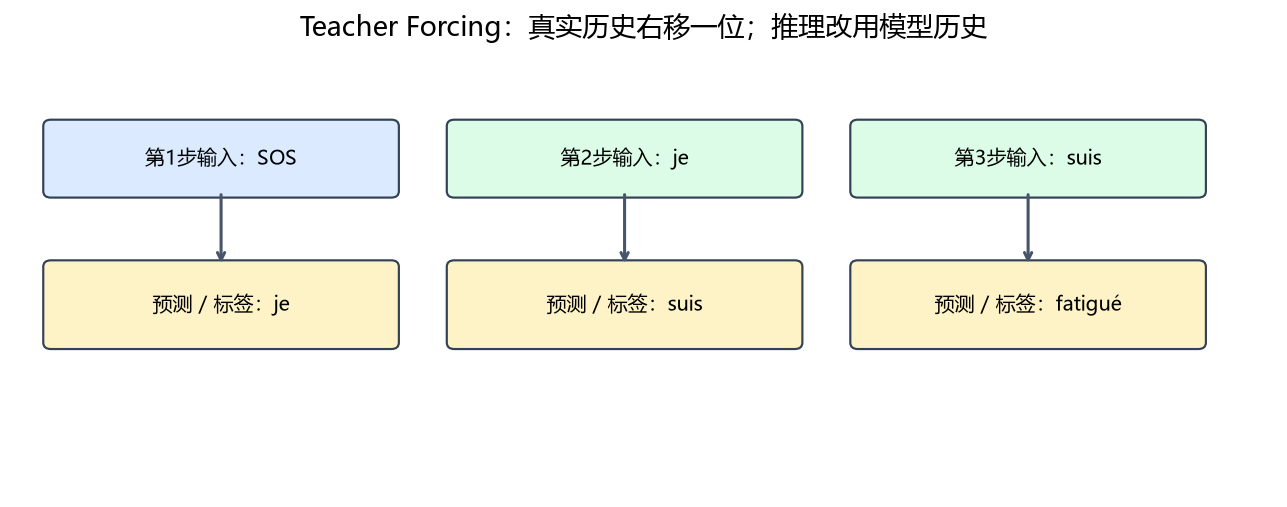


## 4. 编码器：memory 与 hidden

编码器 GRU 读入源句，输出两类信息：

- `memory`：每个源位置的隐藏表示，shape 为 `(B,S,H)`，供 Attention 读取。
- `hidden`：最后有效位置的状态，shape 为 `(1,B,H)`，作为解码器初始状态。

packing 的作用是让 GRU 不在 `PAD` 上继续更新状态。仅仅把 `PAD` 的 embedding 置零并不能消除 GRU 的 bias 和递归状态影响。

```python
EMBED_DIM, HIDDEN_DIM = 24, 32

class Encoder(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMBED_DIM, padding_idx=PAD)
        self.gru = nn.GRU(EMBED_DIM, HIDDEN_DIM, batch_first=True)
    def forward(self, source, lengths):
        embedded = self.embedding(source)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True,
                                       enforce_sorted=False)
        packed_out, hidden = self.gru(packed)
        memory, _ = pad_packed_sequence(packed_out, batch_first=True,
                                        total_length=source.shape[1])
        return memory, hidden

encoder = Encoder(len(src_vocab)).to(DEVICE)
memory, hidden = encoder(src, src_len)
assert memory.shape == (src.shape[0], src.shape[1], HIDDEN_DIM)
assert hidden.shape == (1, src.shape[0], HIDDEN_DIM)
print("memory:", tuple(memory.shape), "hidden:", tuple(hidden.shape))
```

```text
memory: (3, 5, 32) hidden: (1, 3, 32)
```


## 5. Additive Attention 解码器

每一步解码用当前 query（decoder hidden）和所有 encoder key（`memory`）计算分数：

$$e_{t,s}=v^T\tanh(W_qh^{dec}_{t-1}+W_kk_s),\qquad
\alpha_{t}=\operatorname{softmax}(e_t).$$

对补齐位置先填入 `-∞`，再做 softmax，保证 `PAD` 权重严格为 0。课程中的固定位置 Attention 将分数直接映射到 `MAX_LENGTH` 个槽位；这里实现长度无关的 additive attention，能直接处理不同源句长度。

```python
class AdditiveAttention(nn.Module):
    def __init__(self, hidden_dim, score_dim=32):
        super().__init__()
        self.q = nn.Linear(hidden_dim, score_dim, bias=False)
        self.k = nn.Linear(hidden_dim, score_dim)
        self.v = nn.Linear(score_dim, 1, bias=False)
    def forward(self, query, memory, valid):
        if valid.dtype != torch.bool or valid.shape != memory.shape[:2]:
            raise ValueError("invalid source mask")
        if not valid.any(-1).all(): raise ValueError("no valid source token")
        score = self.v(torch.tanh(self.q(query)[:, None, :] + self.k(memory))).squeeze(-1)
        score = score.masked_fill(~valid, -torch.inf)
        weights = score.softmax(-1)
        context = torch.bmm(weights[:, None, :], memory)[:, 0]
        return context, weights

class AttentionDecoder(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMBED_DIM, padding_idx=PAD)
        self.attention = AdditiveAttention(HIDDEN_DIM)
        self.fuse = nn.Linear(EMBED_DIM + HIDDEN_DIM, HIDDEN_DIM)
        self.gru = nn.GRU(HIDDEN_DIM, HIDDEN_DIM, batch_first=True)
        self.out = nn.Linear(HIDDEN_DIM, vocab_size)
    def step(self, token, hidden, memory, valid):
        embedded = self.embedding(token)[:, 0]
        context, weights = self.attention(hidden[-1], memory, valid)
        fused = F.relu(self.fuse(torch.cat([embedded, context], dim=-1)))[:, None]
        decoded, next_hidden = self.gru(fused, hidden)
        return self.out(decoded), next_hidden, weights

decoder = AttentionDecoder(len(tgt_vocab)).to(DEVICE)
logits, next_hidden, weights = decoder.step(
    torch.full((src.shape[0], 1), SOS, dtype=torch.long), hidden, memory, src_valid)
assert logits.shape == (src.shape[0], 1, len(tgt_vocab))
assert torch.all(weights[~src_valid] == 0)
torch.testing.assert_close(weights.sum(-1), torch.ones(src.shape[0]))
print("one-step logits:", tuple(logits.shape), "attention:", tuple(weights.shape))
```

```text
one-step logits: (3, 1, 25) attention: (3, 5)
```


## 6. 形状转换：view、reshape 和 contiguous

day07 第05节单独演示 `view()`。它改变形状但不改变元素的逻辑顺序，总元素数必须相等，且底层 stride 必须兼容。`transpose()` 后的张量常常不连续，`view()` 可能失败；用 `contiguous().view()` 或 `reshape()`。`reshape()` 必要时会复制，因此不能一概认为它总是共享存储。

分类损失需要 `(N,V)` 和 `(N,)`，所以 `(B,T,V)` 变为 `(B*T,V)`，目标 `(B,T)` 变为 `(B*T,)`；它们使用同样的展开顺序，位置才一一对应。

```python
shape_probe = torch.arange(24).reshape(2, 3, 4)
transposed = shape_probe.transpose(1, 2)
assert not transposed.is_contiguous()
try:
    transposed.view(2, -1)
except RuntimeError:
    print("transpose then view rejected: stride is incompatible")
else:
    raise AssertionError("this probe should be non-viewable")
torch.testing.assert_close(transposed.reshape(2, -1), transposed.contiguous().view(2, -1))
print("reshape result shape:", tuple(transposed.reshape(2, -1).shape))
```

```text
transpose then view rejected: stride is incompatible
reshape result shape: (2, 12)
```


## 7. 解码器验证：padding 不能参与竞争

把 masked memory 改成巨大值，真实输出和权重应该不变；再增加额外的 padding 槽位，结果也应保持一致。这比只检查 shape 更能确认 mask 和变长接口真正生效。

```python
with torch.no_grad():
    start = torch.full((len(src), 1), SOS, dtype=torch.long)
    clean_logits, clean_hidden, clean_w = decoder.step(start, hidden, memory, src_valid)
    changed_memory = memory.clone(); changed_memory[~src_valid] = 1000.
    other_logits, other_hidden, other_w = decoder.step(start, hidden, changed_memory, src_valid)
    torch.testing.assert_close(clean_logits, other_logits)
    torch.testing.assert_close(clean_hidden, other_hidden)
    torch.testing.assert_close(clean_w, other_w)
    padded_memory = F.pad(memory, (0, 0, 0, 3))
    padded_mask = F.pad(src_valid, (0, 3), value=False)
    padded_logits, _, padded_w = decoder.step(start, hidden, padded_memory, padded_mask)
    torch.testing.assert_close(clean_logits, padded_logits)
    torch.testing.assert_close(clean_w, padded_w[:, :memory.shape[1]])
    assert torch.all(padded_w[:, memory.shape[1]:] == 0)
try:
    decoder.step(start, hidden, memory, torch.zeros_like(src_valid))
except ValueError: print("all-masked source rejected")
else: raise AssertionError("all-masked softmax would be invalid")
print("masked value mutation and extra padding invariance passed")
```

```text
all-masked source rejected
masked value mutation and extra padding invariance passed
```


## 8. Teacher-forced forward 与损失

训练函数要沿目标序列循环：每一步得到 `(B,1,V)` 的 logits 和 `(B,S)` 的注意力。把时间步拼接后得到 `(B,T,V)`，再用 `CrossEntropyLoss(ignore_index=PAD)` 只统计真实目标 token。

课程示例使用 `LogSoftmax + NLLLoss` 也可以；本篇用 `CrossEntropyLoss`，它内部包含等价的 `log_softmax`。

```python
def teacher_forced_forward(source, lengths, target, teacher_forcing_ratio=1.0):
    memory, state = encoder(source, lengths)
    valid = torch.arange(source.shape[1])[None, :] < lengths[:, None]
    token = torch.full((source.shape[0], 1), SOS, dtype=torch.long)
    logits_all, weights_all = [], []
    for t in range(target.shape[1]):
        step_logits, state, step_weights = decoder.step(token, state, memory, valid)
        logits_all.append(step_logits)
        weights_all.append(step_weights)
        use_teacher = teacher_forcing_ratio >= 1.0 or (
            teacher_forcing_ratio > 0 and torch.rand(()) < teacher_forcing_ratio)
        token = target[:, t:t+1] if use_teacher else step_logits.argmax(-1).detach()
    return torch.cat(logits_all, 1), torch.stack(weights_all, 1)

logits, attention = teacher_forced_forward(src, src_len, tgt, teacher_forcing_ratio=1.0)
loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), tgt.reshape(-1), ignore_index=PAD)
print("logits:", tuple(logits.shape), "attention:", tuple(attention.shape))
print("non-PAD target tokens:", int((tgt != PAD).sum()), "loss:", round(loss.item(), 4))
```

```text
logits: (3, 5, 25) attention: (3, 5, 5)
non-PAD target tokens: 13 loss: 3.2206
```


## 9. 单批次更新：先确认梯度和loss

优化顺序是 `zero_grad → forward → loss → backward → clip → step`。这里用一个新的模型副本做单步 SGD，不改变随后完整训练的初始模型。encoder、decoder 和 attention 必须都收到有限、非零梯度。

对于 mixed Teacher Forcing，本篇按**每个时间步、整个 batch**抽取一次决定；课件按一条序列抽取一次，两者是不同的训练选择。0.5 表示使用真实历史输入的概率，不表示训练准确率。预测 token 使用 `argmax().detach()`，离散选择不会通过 token ID 反向传播，但 hidden 和 memory 的梯度仍能正常传递。

```python
import copy
single_encoder, single_decoder = copy.deepcopy(encoder), copy.deepcopy(decoder)
single_memory, single_state = single_encoder(src, src_len)
single_logits = []
single_inputs = shift_right(tgt)
for t in range(tgt.shape[1]):
    step, single_state, _ = single_decoder.step(single_inputs[:, t:t+1], single_state,
                                               single_memory, src_valid)
    single_logits.append(step)
single_logits = torch.cat(single_logits, 1)
single_loss = F.cross_entropy(single_logits.reshape(-1, len(tgt_vocab)), tgt.reshape(-1),
                              ignore_index=PAD)
torch.testing.assert_close(single_loss, F.cross_entropy(single_logits[tgt != PAD], tgt[tgt != PAD]))
single_params = list(single_encoder.parameters()) + list(single_decoder.parameters())
single_old = [p.detach().clone() for p in single_params]
single_optimizer = torch.optim.SGD(single_params, lr=0.02)
single_optimizer.zero_grad(set_to_none=True); single_loss.backward()
for model in (single_encoder, single_decoder, single_decoder.attention):
    grads = [p.grad for p in model.parameters()]
    assert all(g is not None and torch.isfinite(g).all() for g in grads)
    assert sum(g.abs().sum().item() for g in grads) > 0
single_norm = float(nn.utils.clip_grad_norm_(single_params, 1.0))
single_optimizer.step()
assert any(not torch.equal(old, new) for old, new in zip(single_old, single_params))
print("single batch mean CE:", round(single_loss.item(), 6), "gradient norm:", round(single_norm, 6))
print("encoder/decoder/attention finite gradients and parameter update passed")
```

```text
single batch mean CE: 3.220584 gradient norm: 0.584822
encoder/decoder/attention finite gradients and parameter update passed
```


## 10. 单批次训练与完整训练

先做一次单批次更新，确认梯度存在、参数真的改变，再进入完整 epoch。训练损失应该按**有效 token 数**求平均，并且保留最后一个不足 `batch_size` 的尾 batch。训练阶段使用 `model.train()`；评估/预测阶段使用 `eval()` 和 `torch.no_grad()`。

Teacher Forcing 比例设为 0.5 后，训练中有机会接触模型自己的历史预测；是否改善推理表现仍需在 dev 集验证。极小数据上的损失下降不能证明泛化翻译能力。

```python
def run_epoch(loader, optimizer=None, teacher_forcing_ratio=0.5):
    training = optimizer is not None
    encoder.train(training); decoder.train(training)
    total_loss, total_tokens = 0.0, 0
    for source, target, lengths, *_ in loader:
        if training: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits, _ = teacher_forced_forward(source, lengths, target, teacher_forcing_ratio)
            token_count = int((target != PAD).sum())
            batch_loss_sum = F.cross_entropy(logits.reshape(-1, logits.shape[-1]),
                                             target.reshape(-1), ignore_index=PAD,
                                             reduction="sum")
        if training:
            (batch_loss_sum / token_count).backward()
            torch.nn.utils.clip_grad_norm_(
                list(encoder.parameters()) + list(decoder.parameters()), 1.0)
            optimizer.step()
        total_loss += batch_loss_sum.item(); total_tokens += token_count
    return total_loss / total_tokens

optimizer = torch.optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=0.01)
before = run_epoch(train_loader, optimizer=None, teacher_forcing_ratio=1.0)
history = []
for epoch in range(1, 121):
    train_loss = run_epoch(train_loader, optimizer, teacher_forcing_ratio=0.5)
    history.append(train_loss)
print("loss before:", round(before, 4), "loss after:", round(history[-1], 4))
print("epochs:", len(history), "best:", round(min(history), 4))
train_tf_after = run_epoch(train_loader, optimizer=None, teacher_forcing_ratio=1.0)
print("final train teacher-forced mean CE:", round(train_tf_after, 6))
```

```text
loss before: 3.2153 loss after: 0.0038
epochs: 120 best: 0.0038
final train teacher-forced mean CE: 0.003717
```


## 11. 训练曲线：明确在比较哪一种loss

曲线绘制每轮 mixed Teacher Forcing（比例0.5）的在线训练 token mean CE：同一轮不同 batch 对应更新过程中的不同参数。它会随抽样波动，不保证单调下降。最终另用固定参数、全 Teacher Forcing 在 train/dev 上评估，指标定义才一致。

本篇为了快速演示使用 E=24、H=32、Adam lr=0.01、120轮；课件示例是 H=256、lr=1e-4、1轮。示例参数不能直接套用到完整数据。

```python
fig, ax = plt.subplots(figsize=(7.2, 3.4), dpi=130)
ax.plot(range(1, len(history) + 1), history, color="#2563eb", linewidth=2)
ax.set(xlabel="epoch", ylabel="token mean CE", title="Tiny corpus: mixed teacher forcing (0.5)")
ax.grid(alpha=.25); fig.tight_layout(); plt.show(); plt.close(fig)
tail_loader = DataLoader(TranslationDataset(train_pairs), batch_size=3, collate_fn=collate)
assert [len(b[0]) for b in tail_loader] == [3, 3, 2]
dev_loader = DataLoader(TranslationDataset(dev_pairs), batch_size=3, collate_fn=collate)
dev_tf_loss = run_epoch(dev_loader, optimizer=None, teacher_forcing_ratio=1.0)
print("tail batches:", [len(b[0]) for b in tail_loader])
print("final train/dev teacher-forced CE:", round(train_tf_after, 6), round(dev_tf_loss, 6))
```

```text
tail batches: [3, 3, 2]
final train/dev teacher-forced CE: 0.003717 2.676212
```

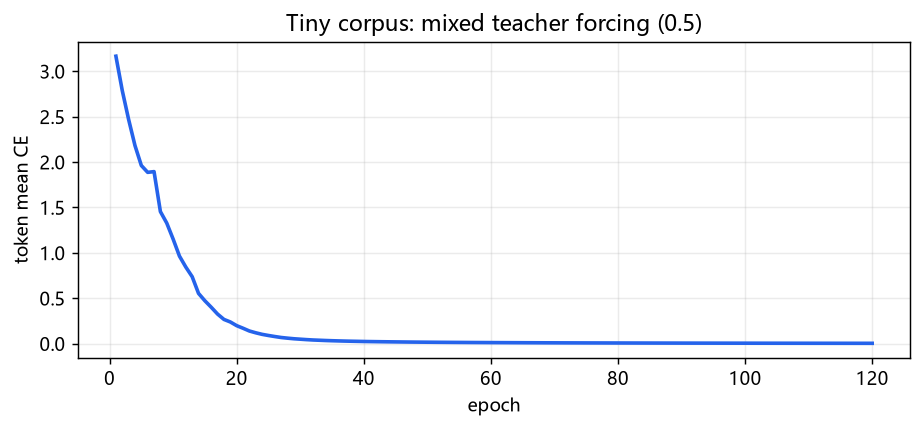


## 12. 保存与恢复：模型权重必须配合词表

相同的整数 ID，只有在同一词表顺序下才代表同一单词。checkpoint 至少需要权重、词表顺序、特殊 token ID、tokenizer版本和结构配置；若要继续训练，还需 optimizer、epoch 和随机状态。正式使用应优先加载自己生成且可信的 checkpoint。

这里通过内存缓冲区演示保存和重载，不会在笔记旁生成额外文件。使用 `map_location='cpu'`、`weights_only=True`、`strict=True`；检查模型恢复后 logits 完全一致。`strict=False` 只允许缺失/多余 key，不会自动解决参数 shape 不匹配。

```python
encoder.eval(); decoder.eval()
checkpoint = {
    "encoder": encoder.state_dict(), "decoder": decoder.state_dict(),
    "source_vocab": src_vocab.idx2word, "target_vocab": tgt_vocab.idx2word,
    "special_ids": {"PAD":PAD, "SOS":SOS, "EOS":EOS, "UNK":UNK},
    "config": {"embedding_dim":EMBED_DIM, "hidden_dim":HIDDEN_DIM, "score_dim":32},
    "tokenizer_version":"nfc-lower-apostrophe-regex-v1", "epoch":120,
    "optimizer":optimizer.state_dict(),
}
buffer = io.BytesIO(); torch.save(checkpoint, buffer); buffer.seek(0)
restored = torch.load(buffer, map_location="cpu", weights_only=True)
assert restored["source_vocab"] == src_vocab.idx2word
assert restored["target_vocab"] == tgt_vocab.idx2word
assert restored["config"] == {"embedding_dim":24, "hidden_dim":32, "score_dim":32}
restored_encoder = Encoder(len(restored["source_vocab"]))
restored_decoder = AttentionDecoder(len(restored["target_vocab"]))
restored_encoder.load_state_dict(restored["encoder"], strict=True)
restored_decoder.load_state_dict(restored["decoder"], strict=True)
with torch.no_grad():
    current_m, current_h = encoder(src, src_len)
    restored_m, restored_h = restored_encoder(src, src_len)
    start = torch.full((len(src), 1), SOS, dtype=torch.long)
    current_l, _, _ = decoder.step(start, current_h, current_m, src_valid)
    restored_l, _, _ = restored_decoder.step(start, restored_h, restored_m, src_valid)
    torch.testing.assert_close(current_l, restored_l, atol=0, rtol=0)
print("checkpoint round-trip: logits exactly equal; bytes:", buffer.getbuffer().nbytes)
```

```text
checkpoint round-trip: logits exactly equal; bytes: 234827
```


## 13. Greedy prediction：推理时不再喂真实答案

预测函数只接收源句：编码一次，随后每步把上一步的 `argmax` 作为下一步输入，直到生成 `EOS` 或达到安全上限。训练时的 Teacher Forcing 输出不能直接当成真实推理效果；评估应在未参与训练的句子上进行，并报告 exact match、token accuracy 或 BLEU 等指标。

```python
def greedy_decode(source_tokens, max_steps=12):
    if max_steps < 1: raise ValueError("max_steps must be positive")
    encoder.eval(); decoder.eval()
    source = src_vocab.encode(source_tokens)[None]
    lengths = torch.tensor([source.shape[1]])
    with torch.no_grad():
        memory, state = encoder(source, lengths)
        valid = torch.ones(1, source.shape[1], dtype=torch.bool)
        token = torch.tensor([[SOS]])
        generated, trace, ended = [], [], False
        for _ in range(max_steps):
            step_logits, state, step_weights = decoder.step(token, state, memory, valid)
            scores = step_logits[0, 0].clone()
            scores[PAD] = scores[SOS] = -torch.inf
            next_id = int(scores.argmax())
            trace.append(step_weights[0].tolist())
            generated.append(next_id)
            if next_id == EOS:
                ended = True
                break
            token = torch.tensor([[next_id]])
    return {"ids": generated, "words": tgt_vocab.decode(generated),
            "attention": np.asarray(trace), "ended": ended}

for source_tokens, target_tokens in test_pairs:
    result = greedy_decode(source_tokens)
    print("EN:", " ".join(source_tokens))
    print("gold:", " ".join(target_tokens), "| pred:", " ".join(result["words"]),
          "| EOS:", result["ended"])
```

```text
EN: you are here .
gold: tu es ici . | pred: nous sommes ici . <EOS> | EOS: True
EN: she is calm .
gold: elle est calme . | pred: il est calme . <EOS> | EOS: True
```


## 14. 生成结果：区分训练记忆与未见句子

下表来自实际 greedy decode，保留真实法文参考。对每组句子比较包含 EOS 的 token ID 序列；若目标有词表外词，编码成 UNK 的 exact match 不能代表原文逐字正确，因此本篇同时报告目标 OOV 数。dev/test 分别仅2对，不足以形成稳定的质量估计。

Teacher-forced dev CE 测的是“给定真实历史”的预测损失；greedy exact match 测的是完整自回归输出，两者不能互相替代。不用测试集挑选 epoch，示例固定训练120轮。

```python
generation_rows = []
generation_metrics = {}
for split_name, pairs in (("train",train_pairs), ("dev",dev_pairs), ("test",test_pairs)):
    matches, ended_count, oov = 0, 0, 0
    for source_tokens, target_tokens in pairs:
        result = greedy_decode(source_tokens)
        gold = tgt_vocab.encode(target_tokens).tolist()
        matches += int(result["ids"] == gold)
        ended_count += int(result["ended"])
        oov += sum(t not in tgt_vocab.word2idx for t in target_tokens)
        generation_rows.append({"split":split_name, "source":" ".join(source_tokens),
                                "gold":" ".join(target_tokens), "pred":" ".join(result["words"]),
                                "EOS":result["ended"]})
    generation_metrics[split_name] = {"exact_match":matches, "n":len(pairs),
                                       "EOS":ended_count, "target_OOV":oov}
    print(split_name, generation_metrics[split_name])
assert all(0 <= x["exact_match"] <= x["n"] for x in generation_metrics.values())
# Exactly one generated step when max_steps=1; exposes the stop reason.
limited = greedy_decode(train_pairs[0][0], max_steps=1)
assert len(limited["ids"]) == len(limited["attention"]) == 1
print("one-step cap respected; stopped by EOS:", limited["ended"])
```

```text
train {'exact_match': 8, 'n': 8, 'EOS': 8, 'target_OOV': 0}
dev {'exact_match': 0, 'n': 2, 'EOS': 2, 'target_OOV': 2}
test {'exact_match': 0, 'n': 2, 'EOS': 2, 'target_OOV': 2}
one-step cap respected; stopped by EOS: False
```


|集合|英文输入|真实参考|greedy输出（包含EOS）|生成EOS|
|---|---|---|---|---|
|train|`go !`|`va !`|`va ! <EOS>`|True|
|train|`i am cold .`|`j'ai froid .`|`j'ai froid . <EOS>`|True|
|train|`i am tired .`|`je suis fatigué .`|`je suis fatigué . <EOS>`|True|
|train|`he is calm .`|`il est calme .`|`il est calme . <EOS>`|True|
|train|`she is ready .`|`elle est prête .`|`elle est prête . <EOS>`|True|
|train|`we are here .`|`nous sommes ici .`|`nous sommes ici . <EOS>`|True|
|train|`thank you .`|`merci .`|`merci . <EOS>`|True|
|train|`they are late .`|`ils sont en retard .`|`ils sont en retard . <EOS>`|True|
|dev|`i am ready .`|`je suis prêt .`|`j'ai froid . <EOS>`|True|
|dev|`we are tired .`|`nous sommes fatigués .`|`nous sommes ici . <EOS>`|True|
|test|`you are here .`|`tu es ici .`|`nous sommes ici . <EOS>`|True|
|test|`she is calm .`|`elle est calme .`|`il est calme . <EOS>`|True|

## 15. 注意力热力图：行是生成步，列是源位置

选择训练句 `I am tired.`，便于观察一个已拟合样例。热力图每行按 softmax 和为1，最后一行若存在应标记 EOS；保留源 EOS 列，裁掉未使用的目标行。这里显示真实预测词作为纵轴，避免把 teacher-forced 标签或错配的参考译文当成输出。

颜色表示权重分配；模型可能依赖多个词或整体上下文，不要求热力图严格形成对角线，也不能仅凭图判断翻译质量。

```python
plot_source = train_pairs[2][0]
plot_result = greedy_decode(plot_source)
plot_source_ids = src_vocab.encode(plot_source)
plot_attention = plot_result["attention"]
assert plot_attention.shape == (len(plot_result["ids"]), len(plot_source_ids))
np.testing.assert_allclose(plot_attention.sum(-1), 1., atol=1e-6)
fig, ax = plt.subplots(figsize=(7.2, 4.1), dpi=130)
im = ax.imshow(plot_attention, aspect="auto", cmap="magma", vmin=0, vmax=1)
ax.set(xticks=range(len(plot_source_ids)), xticklabels=src_vocab.decode(plot_source_ids),
       yticks=range(len(plot_result["words"])), yticklabels=plot_result["words"],
       xlabel="Source tokens (columns)", ylabel="Generated tokens (rows)",
       title="Trained sample: I am tired.")
fig.colorbar(im, ax=ax, label="attention weight")
fig.tight_layout(); plt.show(); plt.close(fig)
print("heatmap shape:", plot_attention.shape, "prediction:", plot_result["words"])
```

```text
heatmap shape: (5, 5) prediction: ['je', 'suis', 'fatigué', '.', '<EOS>']
```

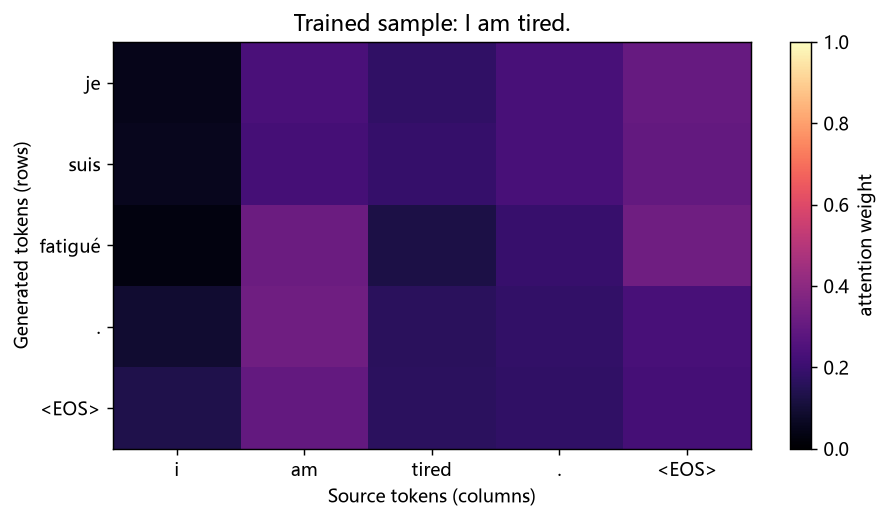


## 16. 训练、预测和评估中的常见坑

1. **重复初始化 hidden**：先初始化 hidden 再调用 encoder；取得最终 hidden 后交给 decoder，避免把它重新置零或在初始化前使用。
2. **忽略尾 batch**：`len(dataset)//batch_size` 会丢掉最后几条样本，应遍历整个 `DataLoader`。
3. **loss 分母错误**：非 Teacher Forcing 分支提前遇到 `EOS` 时，不能仍用完整目标长度做分母；更稳妥的做法是对所有非 `PAD` 标签统一求和。
4. **mask 错位**：注意力矩阵形状通常是 `(B,T,S)`，行对应 decoder 步，列对应 source 位置；课程课件中个别坐标说明需要按张量实际 shape 校正。
5. **checkpoint 信息不全**：除了 `state_dict`，还要保存词表顺序、特殊 token ID、最大长度、归一化方式和模型配置。
6. **只看训练 loss**：小数据很容易记忆训练句，应保留 dev/test，并在 `eval()+no_grad()` 下推理。

## 17. Transformer：day07 的结构预览

当天最后 4 个视频开始介绍 Transformer。它把 Seq2Seq 的“编码器—解码器”范式保留下来，但用**自注意力与前馈网络**替代循环单元：同一层可以并行处理所有位置，再用位置编码补充顺序信息。

核心组件：

- Encoder self-attention：每个源位置读取整个源序列。
- Decoder masked self-attention：只能读取当前及之前的目标位置，避免看到未来答案。
- Cross-attention：decoder query 读取 encoder 输出。
- Position-wise FFN、残差连接、LayerNorm：稳定和扩展深层训练。

Scaled dot-product attention 为

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}+M\right)V.$$

其中 `M` 可以把 padding 或未来位置加上 `-∞`。Transformer 的完整实现和迁移学习放在后续课件，不在本篇展开。

```python
def scaled_dot_product_attention(q, k, v, mask=None):
    dk = q.shape[-1]
    scores = q @ k.transpose(-2, -1) / math.sqrt(dk)
    if mask is not None: scores = scores.masked_fill(~mask, -torch.inf)
    weights = scores.softmax(-1)
    return weights @ v, weights

q = torch.tensor([[[1., 0.], [0., 1.]]])
k = q.clone(); v = torch.tensor([[[10., 0.], [0., 20.]]])
causal = torch.tensor([[[True, False], [True, True]]])
context, attn = scaled_dot_product_attention(q, k, v, causal)
assert torch.all(attn[:, 0, 1] == 0)
print("attention shape:", tuple(attn.shape))
print("first query weights:", attn[0, 0].tolist())
print("first query context:", context[0, 0].tolist())
```

```text
attention shape: (1, 2, 2)
first query weights: [1.0, 0.0]
first query context: [10.0, 0.0]
```


## 18. Transformer架构：沿数据流读四个部分

2017年论文 [Attention Is All You Need](https://arxiv.org/abs/1706.03762) 提出 Transformer，原始模型仍是 encoder–decoder。课件第14—19页分为四部分：

| 部分 | 组成 | 输入/输出 |
| --- | --- | --- |
| 输入 | 源/目标 embedding + positional encoding | IDs → `(B,L,d_model)` |
| 编码器 | N层：多头self-attention、FFN、残差与LayerNorm | source → memory |
| 解码器 | N层：masked self-attention、cross-attention、FFN及连接结构 | 右移目标 + memory → features |
| 输出 | linear projection、softmax或log-softmax | features → 目标词表分布 |

Encoder self-attention 的 Q/K/V 都来自源表示；decoder masked self-attention 的 Q/K/V 都来自目标表示；cross-attention 的 Q 来自 decoder，K/V 来自最终 encoder memory。每一层 decoder 都读取 encoder memory，不是只给第一层。

原论文采用 post-norm：`LayerNorm(x + Sublayer(x))`；常见实现也有 pre-norm，顺序不能混淆。训练时目标已知，可以右移后配合 causal mask 并行计算；自回归推理仍逐 token 生成，不能因为模型可并行训练就说生成过程完全并行。

标准全注意力对长度L的注意力矩阵需要约O(L²)内存。课件中“RNN在20—30词下降、Transformer在40词后较好”是示意对比，不是通用阈值；性能取决于训练、数据、模型和实现。BERT主要使用encoder，GPT主要使用causal decoder，本篇不展开预训练。

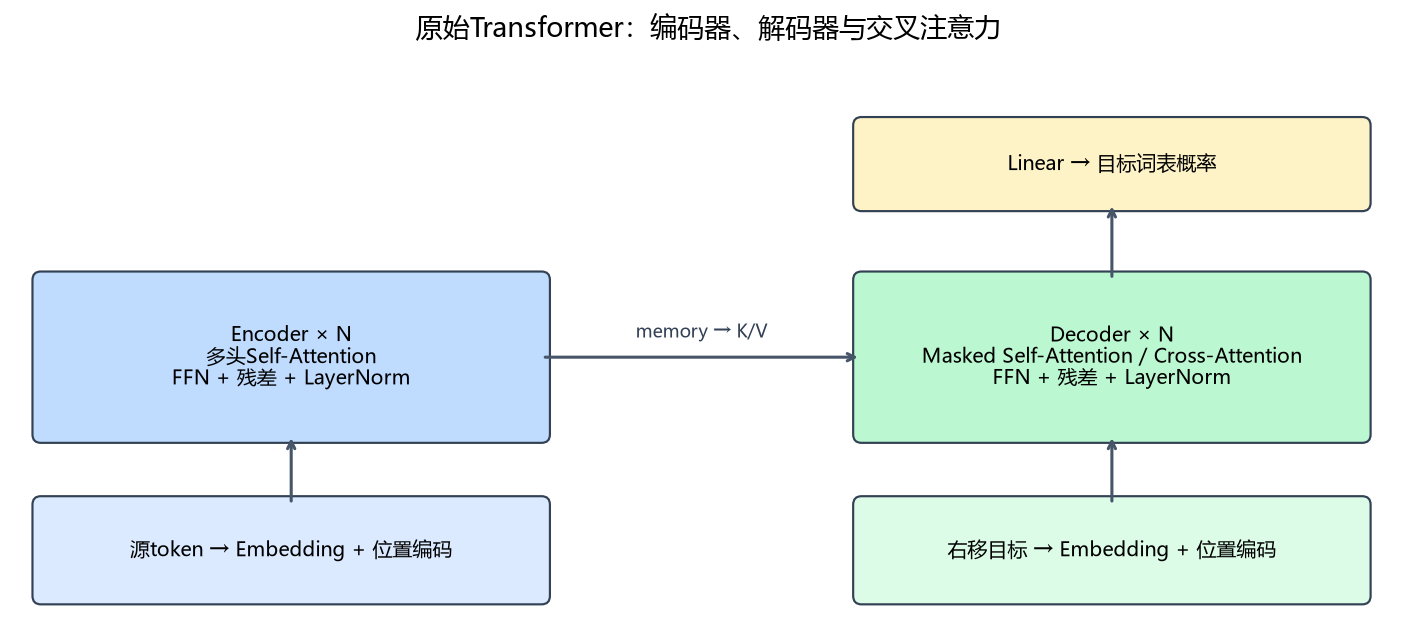


## 19. 两种架构的关系

| 维度 | GRU Seq2Seq | Transformer |
| --- | --- | --- |
| 顺序处理 | 逐时间步循环 | 序列位置可并行计算 |
| 长距离依赖 | 依赖 hidden 传递 | 通过 attention 直接建立连接 |
| 位置信息 | 循环结构隐式提供 | 需要位置编码/位置嵌入 |
| 解码约束 | 每步产生下一个 token | masked self-attention 防止看未来 |
| 资源特点 | 小模型、短序列友好 | 大规模训练和并行硬件友好 |

不要把 Attention 热力图的“亮”直接解释成模型真正学会了因果对齐；它只是当前参数下的权重分布。真正的翻译效果仍需独立测试集和合适指标。

## 20. 复习题与本篇验证

1. 为什么 `EOS` 要作为目标标签参与 loss？
2. `memory` 和 `hidden` 的 shape 分别是什么？
3. Teacher Forcing=1 和 greedy decoding 的输入来源有什么区别？
4. 为什么 Attention mask 必须在 softmax 前应用？
5. Transformer decoder 的 causal mask 防止了什么信息泄漏？

本篇代码在 Python 3.12.13、PyTorch CPU 环境执行；验证了词表只来自训练集、PAD 不参与 loss、注意力 PAD 权重为 0、单批次梯度更新、完整 epoch 尾 batch、greedy EOS 停止和 causal mask。tiny corpus 的损失与预测仅用于流程演示。

实际执行：2026-10-14，Python 3.12.13，NumPy 1.26.4，PyTorch 2.14.1+cpu，CPU。共16个Python代码块顺序运行通过。初始train全Teacher Forcing CE=3.215254；训练120轮后train CE=0.003717，dev CE=2.676212。train/dev/test greedy编码后exact match分别为 8/8、0/2、0/2。目标OOV及EOS结果见上表，勿将训练记忆解释为泛化翻译能力。

## 21. 资料索引与复习答案

来源：[NLP网盘资料](https://pan.baidu.com/s/16JhWSR5VZu0tEQ0EcRJBwA?pwd=1234)，提取码 `1234`。`03-视频/day07`共14节；训练与预测对应《07-案例Seq2Seq英译法案例.pdf》41—63页；Transformer概览对应《08-Tranformer架构和实现.pdf》1—20页（原文件名如此）。

课程课件的具体勘误：第44页重复调用encoder且先使用未初始化hidden；第45页EOS提前停止后仍按完整长度平均loss；第57页使用`strict=False`；第58页第三组英法句不对应；第62页坐标说明与实际`decoder_attentions[step,source_position]`相反。笔记按张量实际含义修正。

复习答案：①EOS是停止标签，需参与监督；②memory=`(B,S,H)`，单层hidden=`(1,B,H)`；③Teacher Forcing输入真实历史，greedy输入预测历史；④softmax前mask使非法位置权重为0；⑤causal mask阻止decoder读取未来目标token。

API参考：[GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html)、[CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)、[Tensor.view](https://docs.pytorch.org/docs/stable/generated/torch.Tensor.view.html)、[torch.load](https://docs.pytorch.org/docs/stable/generated/torch.load.html)。下一篇沿day08资料展开Transformer输入与子层实现。